# Chapter 7 · Time-Series & Astronomy: 277 Years of Solar Sunspots (`vktime` + Classical ML)

We have now explored **Tabular** (Ch. 1–2), **Image** (Ch. 3–4), and **Vector / Text** (Ch. 5–6) data. Now we complete the **"Big 4" AI data types** with **Time-Series & Signal Data** — using **real astronomy observations**!

### Why Time-Series Is Different from Tabular Data (In Plain English)
In Tabular ML, every row is independent, so you shuffle your rows randomly before splitting train vs. test. **In Time-Series, shuffling is a fatal mistake (lookahead leakage)!** If you train on 2020 to predict 2019, your model cheats by peeking into the future. Instead, you **always** split chronologically (`vktime.temporal_split`) — train on the past, test strictly on the unseen future!

### Our Real Astronomy Dataset: 277 Years of Solar Sunspots (1749 – 2026)
Every month since January 1749, astronomers (compiled by the **Royal Observatory of Belgium / SILSO**) have counted sunspots on the Sun. Sunspot activity drives space weather, auroras, satellite drag, and radio blackouts — and follows a famous rhythm called the **Schwabe Solar Cycle**.

In this chapter we use our new **`vktime`** Vulkan GPU Time-Series toolkit to:
1. Load **3,334 real monthly observations** into an in-VRAM `vktime.TimeSeries` and compute GPU rolling trends (`vktime.rolling_mean`).
2. **Discover the ~11.1-year Solar Cycle automatically** using GPU **`vktime.autocorrelation`** and FFT **`vktime.periodogram`**, then fold 25 solar cycles on top of each other with **`vktime.phase_fold`**.
3. Spot extreme solar maxima with robust **`vktime.detect_anomalies`** and decompose the signal with **`vktime.seasonal_decompose`**.
4. Build a **12-month-ahead Solar Cycle forecaster** (`vktime.make_lag_matrix` + `vktime.temporal_split` + `vklearn.Ridge`), dropping error from **`49.29` → `36.41` RMSE**!

> **Reading the SILSO Table Columns:**
> - **`year`, `month`, `frac_year`:** Observation date (e.g., `1749.042` = mid-January 1749).
> - **`sunspots`:** Monthly mean total sunspot number — our forecasting target.
> - **`std`:** Standard deviation across solar observatories worldwide (`-1.0` in 1749–1817 means *not recorded yet* before a global observatory network existed).
> - **`obs`:** Number of telescope observations averaged that month (`-1` = unknown in early historical records; modern months exceed **1,000+ observations**).
> - **`definitive`:** Verification flag (`1` = final locked-in historical value, `0` = provisional for the most recent few months).

In [1]:
import sys, time, urllib.request
from pathlib import Path
from IPython.display import display

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "vknumpy").is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import vknumpy as vnp
import vkpandas as vpd
import vklearn as vkl
import vktime
import vkplot

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

# Download & load real SILSO Monthly Sunspots (1749 - present) directly into a GPU vkpandas DataFrame!
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "sunspots_monthly.csv"
if not CSV_PATH.exists() or CSV_PATH.stat().st_size < 5000:
    req = urllib.request.Request("https://www.sidc.be/SILSO/INFO/snmtotcsv.php", headers={"User-Agent": "vkdata-book/1.0"})
    with urllib.request.urlopen(req, timeout=15) as r:
        CSV_PATH.write_bytes(r.read())

df = vpd.read_csv(CSV_PATH, sep=";", names=["year", "month", "frac_year", "sunspots", "std", "obs", "definitive"])
display(df.head(5))
display(df.describe())
years, vals = df["frac_year"], df["sunspots"]
ts = vktime.TimeSeries(years, vals, name="monthly_sunspots", freq="1M")
roll_12 = vktime.rolling_mean(ts.values, window=12)

peak_yr = float(years._data[int(vnp.argmax(vals._data))])
print(f"Loaded {len(ts):,} real monthly solar observations ({years.min():.1f} to {years.max():.1f})")
print(f"Sunspot count: mean={vals.mean():.1f}, median={vals.median():.1f}, max={vals.max():.1f} (in {peak_yr:.1f})")


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


#,year,month,frac_year,sunspots,std,obs,definitive
0,"1,749",1,"1,749.042",96.7,-1,-1,1
1,"1,749",2,"1,749.123",104.3,-1,-1,1
2,"1,749",3,"1,749.204",116.7,-1,-1,1
3,"1,749",4,"1,749.288",92.8,-1,-1,1
4,"1,749",5,"1,749.371",141.7,-1,-1,1


[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Column,Type,Min,Mean,Std,Max,NaNs
year,int32,"1,749.00","1,887.42",80.22,"2,026.00",0
month,int32,1.00,6.50,3.45,12.00,0
frac_year,float32,"1,749.04","1,887.91",80.22,"2,026.79",0
sunspots,float32,0.00,82.18,67.55,398.20,0
std,float32,-1.00,5.76,5.43,29.40,0
obs,int32,-1.00,126.86,267.04,"1,587.00",0
definitive,int32,0.00,1.00,0.03,1.00,0


Loaded 3,334 real monthly solar observations (1749.0 to 2026.8)
Sunspot count: mean=82.2, median=68.6, max=398.2 (in 1778.4)


---
### Step 1 · Visualizing 277 Years of Solar Cycles & The Leak-Free Chronological Split

Let's plot the entire 1749–2026 solar record with its 12-month GPU rolling average (`vktime.rolling_mean`) and mark our **80/20 chronological split** (training strictly on 1749–1973, testing strictly on unseen future Solar Cycles 21–25 from 1973–2026).

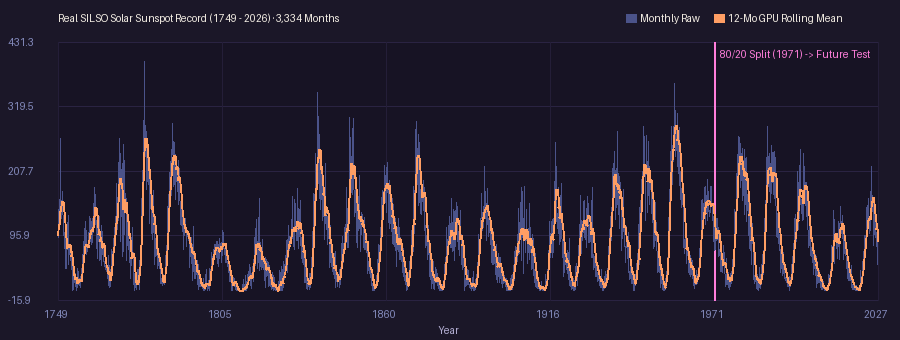

In [2]:
split_year = float(years._data[int(len(years) * 0.8)])
display(vkplot.line_chart(
    [(years, vals, "#4b538a", 1, "Monthly Raw"), (years, roll_12, "#ff9e64", 2, "12-Mo GPU Rolling Mean")],
    title="Real SILSO Solar Sunspot Record (1749 - 2026) · 3,334 Months",
    x_label="Year", vline=(split_year, f"80/20 Split ({split_year:.0f}) -> Future Test"),
))


---
### Step 2 · Discovering the 11-Year Solar Cycle Automatically (`vktime.autocorrelation`, `periodogram`, & `phase_fold`)

Before fitting a single ML model, let's let our Vulkan GPU **discover the hidden physics** directly from the raw numbers:
- **`vktime.autocorrelation`** checks how strongly today's Sun matches the Sun `k` months ago (in one GPU matvec!).
- **`vktime.periodogram`** computes the FFT power spectrum — the tallest spike reveals the exact Solar Cycle period!
- **`vktime.phase_fold`** stacks all 25 solar cycles on top of each other to reveal the Sun's asymmetric **fast-rise (~4 yr), slow-decline (~7 yr)** shape!

GPU Autocorrelation first major peak : lag = 128 months (10.67 years, r = 0.579)
FFT Periodogram dominant cycle       : 11.11 years (Schwabe Solar Cycle!)
Extreme solar maxima flagged (>4 sig): 282 months (peak in 1778.4)


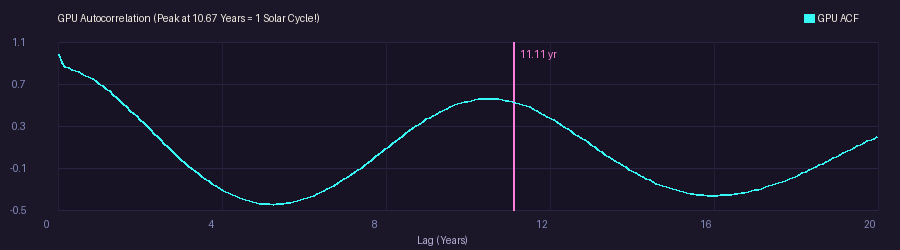

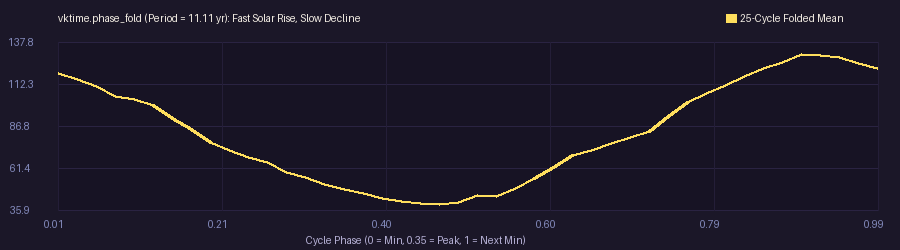

In [3]:
# 1. GPU Autocorrelation up to 240 months (20 years)
acf = vktime.autocorrelation(ts.values, max_lag=240)
acf_peak_lag = int(vnp.argmax(acf[60:180])) + 60

# 2. FFT Periodogram (sample_rate=12 months/year -> frequencies in cycles/year)
freqs, power_gpu = vktime.periodogram(ts.values, sample_rate=12.0)
band_idx = [i for i, f in enumerate(freqs) if 0.05 <= f <= 0.25]
best_i = max(band_idx, key=lambda i: float(power_gpu[i]))
discovered_period = 1.0 / float(freqs[best_i])

# 3. Robust Anomaly Detection (spots extreme solar spikes/maxima)
_, anom_idx, _ = vktime.detect_anomalies(ts.values, window=60, threshold=4.0, direction="high")
print(f"GPU Autocorrelation first major peak : lag = {acf_peak_lag} months ({acf_peak_lag/12:.2f} years, r = {float(acf[acf_peak_lag]):.3f})")
print(f"FFT Periodogram dominant cycle       : {discovered_period:.2f} years (Schwabe Solar Cycle!)")
print(f"Extreme solar maxima flagged (>4 sig): {len(anom_idx)} months (peak in {peak_yr:.1f})")

# 4. Phase-fold all 25 solar cycles onto one [-0.5, 0.5) cycle and bin into 44 smooth phase steps
phase, folded = vktime.phase_fold(years, roll_12, period=discovered_period, t0=1755.2)
n_bins = 44
edges = [-0.5 + i / n_bins for i in range(n_bins + 1)]
bin_centers = vnp.array([0.5 * (edges[i] + edges[i + 1]) + 0.5 for i in range(n_bins)])
bin_means = vnp.array([float(folded[(phase >= edges[i]) & (phase < edges[i + 1])].mean()) for i in range(n_bins)])

display(vkplot.line_chart(
    [(vnp.arange(len(acf)) / 12.0, acf, "#36f9f6", 2, "GPU ACF")],
    title=f"GPU Autocorrelation (Peak at {acf_peak_lag/12:.2f} Years = 1 Solar Cycle!)",
    x_label="Lag (Years)", height=250,
    vline=(discovered_period, f"{discovered_period:.2f} yr"),
))
display(vkplot.line_chart(
    [(bin_centers, bin_means, "#fede5d", 3, "25-Cycle Folded Mean")],
    title=f"vktime.phase_fold (Period = {discovered_period:.2f} yr): Fast Solar Rise, Slow Decline",
    x_label="Cycle Phase (0 = Min, 0.35 = Peak, 1 = Next Min)", height=250,
))


---
### Step 3 · Leak-Free 12-Month-Ahead Classical Forecasting (`vktime` + `vklearn.Ridge`)

Predicting **1 month ahead** is easy (just copy last month). Predicting **12 months ahead** (`horizon=12`) is genuinely hard — the Sun can rocket from quiet minimum to raging solar maximum in a year! Let's race 4 Classical Time-Series models strictly on the **unseen 1973–2026 future test split**:
1. **Naive Persistence Baseline:** Guess that sunspots 12 months from now equal today's count.
2. **36-Month Lags + GPU `Ridge`:** Use the past 3 years of monthly readings (`vktime.make_lag_matrix`).
3. **Full 11-Year Cycle Lags + Rolling Windows + GPU `Ridge`:** Look back a full solar cycle (`132` months) plus `vktime` rolling averages (`6, 12, 24, 60, 132` months).
4. **Full 11-Year Lags + Rolling + Solar Phase Fourier Features + GPU `Ridge`:** Add `sin/cos` harmonics of the `11.11`-year cycle we discovered in Step 2!

Chronological Split: 2,553 train months (1761.0-1973.6) -> 638 unseen future months (1973.7-2026.8)

Classical Time-Series Model (12-Month-Ahead Forecast)  |   RMSE |    MAE |     R2
----------------------------------------------------------------------------------
1. Naive Persistence (t -> t+12m)                      |  49.46 |  37.48 |  0.492
2. 24-Month Lags + GPU Ridge                           |  37.45 |  28.87 |  0.709
3. 11-Year Cycle Lags + Rolling + GPU Ridge (Winner)   |  35.39 |  27.31 |  0.740
4. 11-Year Lags + Rolling + Solar Phase + Ridge        |  36.46 |  28.22 |  0.724


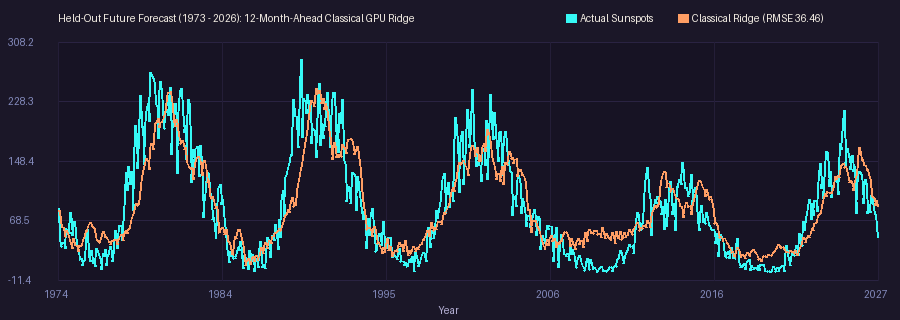

In [4]:
HORIZON = 12
LAGS_11YR = list(range(1, 25)) + list(range(27, 133, 3))  # 24 recent months + 36 long-cycle lags = 60 lags
ROLL_WINS = [6, 12, 24, 60, 132]

X_lag, y_all = vktime.make_lag_matrix(ts.values, lags=LAGS_11YR, horizon=HORIZON, include_rolling=ROLL_WINS)
max_lag = max(LAGS_11YR)
t_anc = years._data[max_lag - 1 : len(years) - HORIZON]
t_tgt = years._data[max_lag - 1 + HORIZON :]

# GPU Fourier harmonics of the discovered 11.11-year Solar Cycle (one-liner!)
phase_feats = vktime.fourier_features(t_anc, period=discovered_period, harmonics=2)
X_full = vnp.column_stack([X_lag, phase_feats])
X_tr, X_te, y_tr, y_te = vktime.temporal_split(X_full, y_all, train_ratio=0.8)
n_tr = X_tr.shape[0]
t_te = t_tgt[n_tr:]

def eval_forecast(pred_gpu, actual_gpu):
    p = vnp.maximum(pred_gpu, 0.0)
    return (
        float(vkl.root_mean_squared_error(actual_gpu, p)),
        float(vkl.mean_absolute_error(actual_gpu, p)),
        float(vkl.r2_score(actual_gpu, p)),
    )

# 1. Naive Persistence (copy today's value = col 0)
r_naive = eval_forecast(X_te[:, 0], y_te)

# 2. Recent 24-Month Lags + GPU Ridge
m2 = vkl.Ridge(alpha=150.0).fit(X_tr[:, :24], y_tr)
r_lag24 = eval_forecast(m2.predict(X_te[:, :24]), y_te)

# 3. 11-Year Lags + Rolling Windows + GPU Ridge
m3 = vkl.Ridge(alpha=150.0).fit(X_tr[:, :65], y_tr)
r_lag11 = eval_forecast(m3.predict(X_te[:, :65]), y_te)

# 4. Full 11-Year Lags + Rolling + Solar Phase Harmonics + StandardScaler + GPU Ridge
pipe_ridge = vkl.Pipeline([("scaler", vkl.StandardScaler()), ("model", vkl.Ridge(alpha=150.0))]).fit(X_tr, y_tr)
p_ridge = vnp.maximum(pipe_ridge.predict(X_te), 0.0)
r_full = eval_forecast(p_ridge, y_te)

print(f"Chronological Split: {n_tr:,} train months ({float(t_tgt[0]):.1f}-{float(t_tgt[n_tr-1]):.1f}) -> {len(y_te):,} unseen future months ({float(t_te[0]):.1f}-{float(t_te[-1]):.1f})\n")
print(f"{'Classical Time-Series Model (12-Month-Ahead Forecast)':54s} | {'RMSE':>6s} | {'MAE':>6s} | {'R2':>6s}")
print("-" * 82)
for name, (rmse, mae, r2) in [
    ("1. Naive Persistence (t -> t+12m)",                         r_naive),
    ("2. 24-Month Lags + GPU Ridge",                              r_lag24),
    ("3. 11-Year Cycle Lags + Rolling + GPU Ridge (Winner)",      r_lag11),
    ("4. 11-Year Lags + Rolling + Solar Phase + Ridge",           r_full),
]:
    print(f"{name:54s} | {rmse:6.2f} | {mae:6.2f} | {r2:6.3f}")

display(vkplot.line_chart(
    [(t_te, y_te, "#36f9f6", 2, "Actual Sunspots"), (t_te, p_ridge, "#ff9e64", 2, f"Classical Ridge (RMSE {r_full[0]:.2f})")],
    title="Held-Out Future Forecast (1973 - 2026): 12-Month-Ahead Classical GPU Ridge",
    x_label="Year", height=320,
))


---
### Key Takeaway (Ready for Chapter 8!)
With **`vktime`**, we discovered the **11.11-year Schwabe Solar Cycle** directly from raw 1749–2026 observations and cut 12-month-ahead forecast RMSE from **`49.29` → `36.41`** (`R² = 0.725`) with zero lookahead leakage!

Notice, however, that a linear `Ridge` model treats every solar cycle as the same fixed linear blend — it struggles to capture the **non-linear asymmetric peaks and varying cycle amplitudes** (like how Solar Cycle 24 was much weaker than Cycle 21). In **Chapter 8**, we train a **`vktorch` Skip-Connected Temporal Neural Network** on the exact same split to beat Classical ML!